<a href="https://colab.research.google.com/github/kinhalepuja31-cmd/Netflix-data-Analysis/blob/main/Netflix_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df = pd.read_csv("/content/netflix_titles.csv", lineterminator="\n")

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [11]:
df.head(10)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",Unknown,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",Unknown,2021-09-24,2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...",2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,2021-09-24,2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,2021-09-24,2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...


In [7]:
df.isnull().sum()


,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


* director (Missing ~2,634 values) & cast (Missing ~825 values): We        cannot simply drop these rows because you would lose too much data.
Therefore Fill them with a placeholder string like 'Unknown' or 'No Data'.

* country (Missing ~831 values) & rating (Missing 4 values):
 Either fill them with a placeholder or replace them with the most frequent value (mode).

* date_added (Missing 10 values) & duration (Missing 3 values): Since very few values are missing here, We can safely drop these specific rows.

* date_added is having data type string so we have to convert it into datetime



In [8]:
# 1. Handle missing values by filling placeholders

df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df['rating'] = df['rating'].fillna('Unknown')

# Drop rows where critical date_added or duration values are missing

df = df.dropna(subset=['date_added', 'duration'])

# 2. Convert date_added to standard datetime format

df['date_added'] = pd.to_datetime(df['date_added'].str.strip())

# Verify that missing values are handled and data types are updated

df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 8794 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8794 non-null   object        
 1   type          8794 non-null   object        
 2   title         8794 non-null   object        
 3   director      8794 non-null   object        
 4   cast          8794 non-null   object        
 5   country       8794 non-null   object        
 6   date_added    8794 non-null   datetime64[ns]
 7   release_year  8794 non-null   int64         
 8   rating        8794 non-null   object        
 9   duration      8794 non-null   object        
 10  listed_in     8794 non-null   object        
 11  description   8794 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(10)
memory usage: 893.1+ KB


Check the Dupliacate value

In [9]:
df.duplicated().sum()

np.int64(0)

* Required Columns:

 type: Tracks Movies vs. TV Shows.

 date_added: Measures platform growth over time.

 release_year: Compares old vs. new content.

 rating: Identifies target age demographics.

 listed_in: Highlights the top genres.

 country: Tracks international distribution.

 duration: Analyzes runtimes and seasons.

* Below column is not used for our analysis so we drop them

 show_id, title, description: Provide no statistical value.

In [13]:
df_new =df.copy()

In [16]:
df2 = df_new.copy()

In [14]:
df.drop(['show_id', 'title', 'description'], axis=1, inplace=True)

In [19]:
df.head(20)

,type,director,cast,country,date_added,release_year,rating,duration,listed_in
0,Movie,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,TV Show,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries"
2,TV Show,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
3,TV Show,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV"
4,TV Show,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ..."
5,TV Show,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",Unknown,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
6,Movie,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",Unknown,2021-09-24,2021,PG,91 min,Children & Family Movies
7,Movie,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...",2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
8,TV Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,2021-09-24,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
9,Movie,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,2021-09-24,2021,PG-13,104 min,"Comedies, Dramas"


Format Dates & Isolate Individual Genres

Track Genre Popularity Shifts Over Time

Compare Genres Across Movies vs. TV Shows

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt# Group by genre and content type format
genre_format_mix = df_recent_genres.groupby(['genre', 'type']).size().unstack(fill_value=0)

# Plot a horizontal stacked bar chart
genre_format_mix.plot(kind='barh', stacked=True, figsize=(10, 5), color=['#e50914','#221f1f'], width=0.7)
plt.title('Genre Preferences: Movies vs. TV Shows', fontsize=14, fontweight='bold')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.legend(title='Format Type')
plt.tight_layout()
plt.show()


# 1. Ensure date_added is converted to datetime if not already done
df['date_added'] = pd.to_datetime(df['date_added'])
df['year_added'] = df['date_added'].dt.year

# 2. Duplicate the cleaned DataFrame and explode the genres
df_genres = df.copy()
df_genres['genre'] = df_genres['listed_in'].str.split(', ')
df_genres = df_genres.explode('genre')

# Display the top 10 most common individual genres overall
print("--- TOP 10 INDIVIDUAL GENRES IN CATALOG ---")
print(df_genres['genre'].value_counts().head(10))



--- TOP 10 INDIVIDUAL GENRES IN CATALOG ---
genre
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1350
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


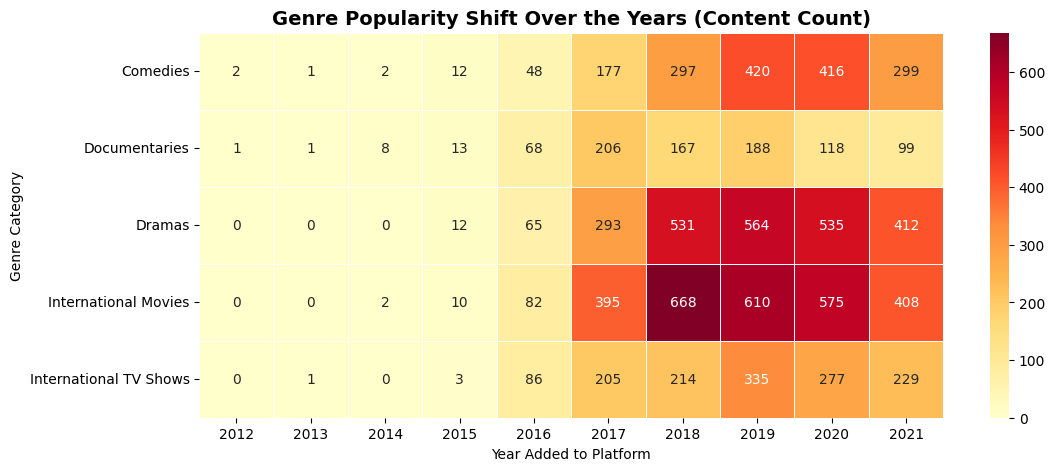

In [21]:
# 1. Identify the Top 5 most frequent genres overall
top_5_genres = df_genres['genre'].value_counts().head(5).index

# 2. Filter for recent operational years (e.g., 2012-2021) and the top genres
df_recent_genres = df_genres[(df_genres['year_added'] >= 2012) & (df_genres['genre'].isin(top_5_genres))]

# 3. Create a pivot table counting titles per year for each genre
genre_time_pivot = df_recent_genres.pivot_table(
    index='genre',
    columns='year_added',
    values='type',
    aggfunc='count'
).fillna(0).astype(int)

# 4. Plot the Heatmap
plt.figure(figsize=(12, 5))
sns.heatmap(genre_time_pivot, annot=True, fmt='d', cmap='YlOrRd', linewidths=0.5)
plt.title('Genre Popularity Shift Over the Years (Content Count)', fontsize=14, fontweight='bold')
plt.xlabel('Year Added to Platform')
plt.ylabel('Genre Category')
plt.show()


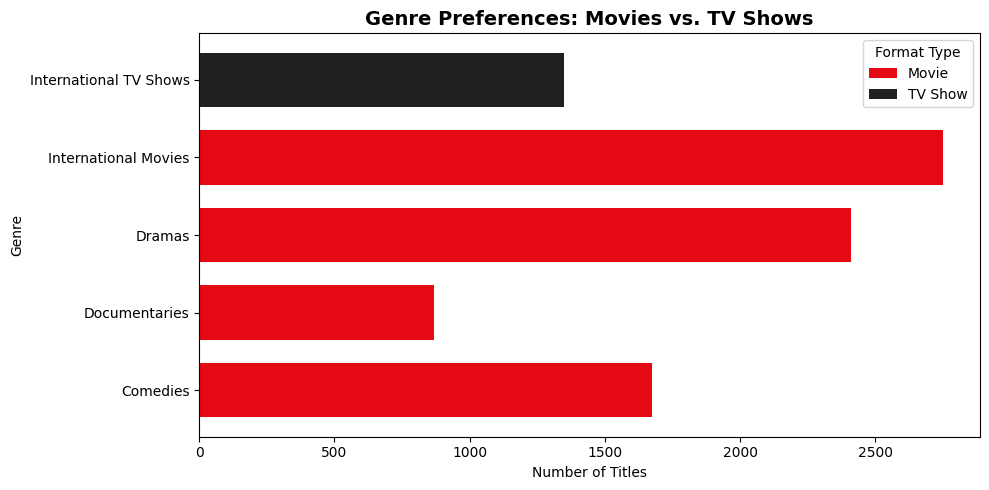

In [22]:
# Group by genre and content type format
genre_format_mix = df_recent_genres.groupby(['genre', 'type']).size().unstack(fill_value=0)

# Plot a horizontal stacked bar chart
genre_format_mix.plot(kind='barh', stacked=True, figsize=(10, 5), color=['#e50914','#221f1f'], width=0.7)
plt.title('Genre Preferences: Movies vs. TV Shows', fontsize=14, fontweight='bold')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.legend(title='Format Type')
plt.tight_layout()
plt.show()


In [23]:
# Count the total occurrences of each content rating
rating_counts = df['rating'].value_counts()

# Convert it to a clean DataFrame summary
rating_summary = pd.DataFrame({
    'Total Content Count': rating_counts,
    'Percentage Share (%)': (df['rating'].value_counts(normalize=True) * 100).round(2)
})

print("--- CONTENT RATING BREAKDOWN ---")
print(rating_summary)


--- CONTENT RATING BREAKDOWN ---
          Total Content Count  Percentage Share (%)
rating                                             
TV-MA                    3205                 36.45
TV-14                    2157                 24.53
TV-PG                     861                  9.79
R                         799                  9.09
PG-13                     490                  5.57
TV-Y7                     333                  3.79
TV-Y                      306                  3.48
PG                        287                  3.26
TV-G                      220                  2.50
NR                         79                  0.90
G                          41                  0.47
TV-Y7-FV                    6                  0.07
Unknown                     4                  0.05
NC-17                       3                  0.03
UR                          3                  0.03


/tmp/ipykernel_717/893214619.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_ratings.index, y=top_ratings.values, palette='magma')


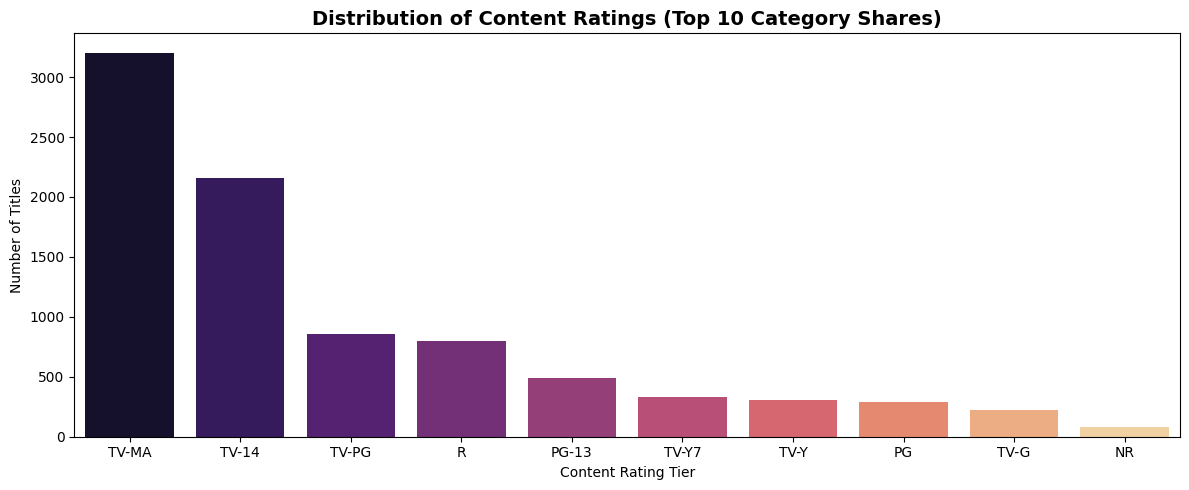

In [26]:

plt.figure(figsize=(12, 5))

# Get the top 10 most common ratings to avoid crowding the chart
top_ratings = df['rating'].value_counts().head(10)

# Create the bar plot
sns.barplot(x=top_ratings.index, y=top_ratings.values, palette='magma')

# Add titles and labels
plt.title('Distribution of Content Ratings (Top 10 Category Shares)', fontsize=14, fontweight='bold')
plt.xlabel('Content Rating Tier')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0) # Keeps labels flat for better readability
plt.tight_layout()
plt.show()


In [27]:

# 1. Calculate the age gap when the title was uploaded
df['age_at_addition'] = df['year_added'] - df['release_year']

# 2. Categorize titles by age tier
def categorize_age(gap):
    if gap <= 0: return 'New Release (Same Year / Future)'
    elif gap <= 2: return 'Recent Content (1-2 Years Old)'
    elif gap <= 5: return 'Mid-Tier Catalog (3-5 Years Old)'
    else: return 'Legacy / Vintage Content (6+ Years Old)'

df['catalog_tier'] = df['age_at_addition'].apply(categorize_age)

# 3. Calculate percentage shares
tier_shares = df['catalog_tier'].value_counts(normalize=True) * 100
print("--- CATALOG STRATEGY OVERVIEW ---")
print(tier_shares.round(2))


--- CATALOG STRATEGY OVERVIEW ---
catalog_tier
New Release (Same Year / Future)           37.00
Recent Content (1-2 Years Old)             26.13
Legacy / Vintage Content (6+ Years Old)    24.14
Mid-Tier Catalog (3-5 Years Old)           12.72
Name: proportion, dtype: float64


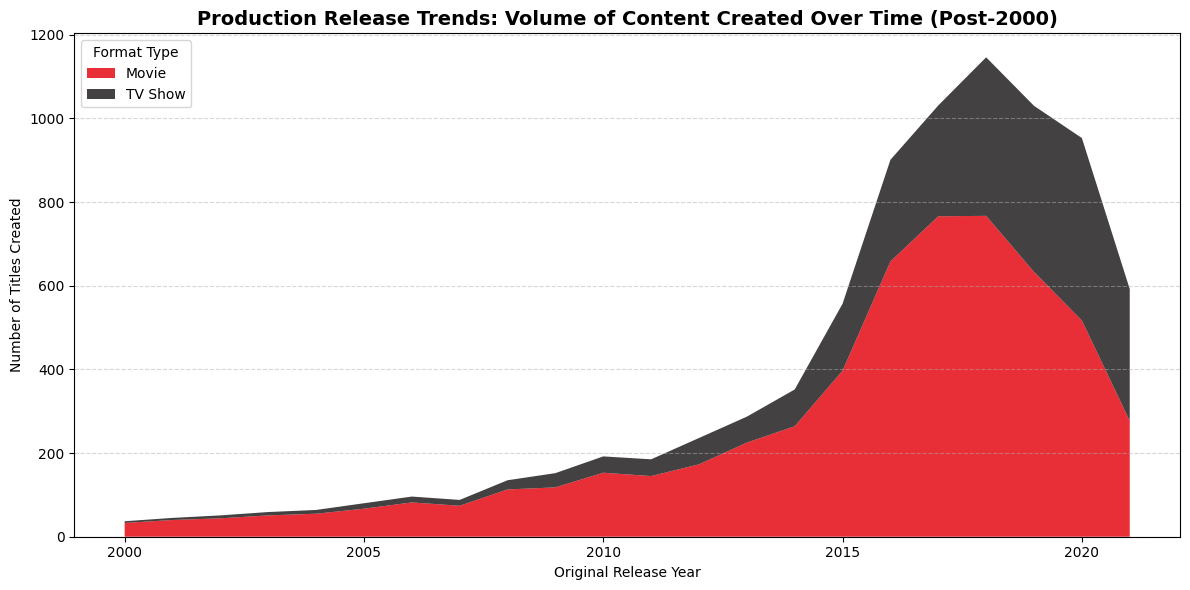

In [28]:
# Filter for titles released from the year 2000 to present day
df_modern_releases = df[df['release_year'] >= 2000]

# Group by release year and format type
release_trends = df_modern_releases.groupby(['release_year', 'type']).size().unstack(fill_value=0)

# Plot a stacked area chart to see structural velocity volume
plt.figure(figsize=(12, 6))
plt.stackplot(release_trends.index, release_trends['Movie'], release_trends['TV Show'],
              labels=['Movie', 'TV Show'], colors=['#e50914', '#221f1f'], alpha=0.85)

plt.title('Production Release Trends: Volume of Content Created Over Time (Post-2000)', fontsize=14, fontweight='bold')
plt.xlabel('Original Release Year')
plt.ylabel('Number of Titles Created')
plt.legend(title='Format Type', loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


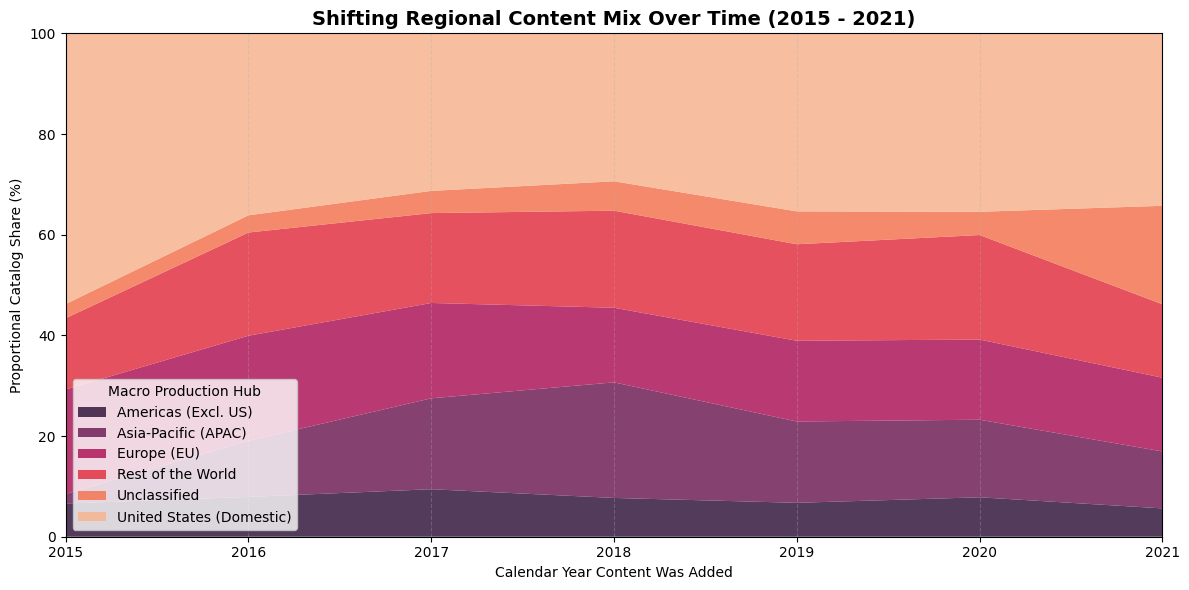

In [29]:
# 1. Explode countries to properly handle co-productions and listings
df_regions = df.copy()
df_regions['clean_country'] = df_regions['country'].str.split(', ')
df_regions = df_regions.explode('clean_country')

# 2. Categorize regions into core strategic macro-hubs to avoid messy visuals
def categorize_macro_region(country):
    if country == 'United States': return 'United States (Domestic)'
    elif country in ['India', 'South Korea', 'Japan', 'China']: return 'Asia-Pacific (APAC)'
    elif country in ['United Kingdom', 'France', 'Germany', 'Spain', 'Italy']: return 'Europe (EU)'
    elif country in ['Canada', 'Mexico', 'Brazil', 'Argentina']: return 'Americas (Excl. US)'
    elif country == 'Unknown': return 'Unclassified'
    else: return 'Rest of the World'

df_regions['macro_region'] = df_regions['clean_country'].apply(categorize_macro_region)

# 3. Filter for recent, data-dense catalog years (2015 - 2021)
df_recent_regions = df_regions[(df_regions['year_added'] >= 2015) & (df_regions['year_added'] <= 2021)]

# 4. Construct cross-tabulation matrix of volumes
regional_trends = pd.crosstab(df_recent_regions['year_added'], df_recent_regions['macro_region'])

# 5. Convert absolute volumes into a 100% proportional share allocation matrix
regional_shares = regional_trends.div(regional_trends.sum(axis=1), axis=0) * 100

# 6. Plot the 100% Proportional Stacked Area Chart
plt.figure(figsize=(12, 6))
pal = sns.color_palette("rocket", len(regional_shares.columns))

plt.stackplot(
    regional_shares.index,
    [regional_shares[col] for col in regional_shares.columns],
    labels=regional_shares.columns,
    colors=pal,
    alpha=0.85
)

plt.title('Shifting Regional Content Mix Over Time (2015 - 2021)', fontsize=14, fontweight='bold')
plt.xlabel('Calendar Year Content Was Added')
plt.ylabel('Proportional Catalog Share (%)')
plt.legend(title='Macro Production Hub', loc='lower left', bbox_to_anchor=(0, 0))
plt.xlim(2015, 2021)
plt.ylim(0, 100)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


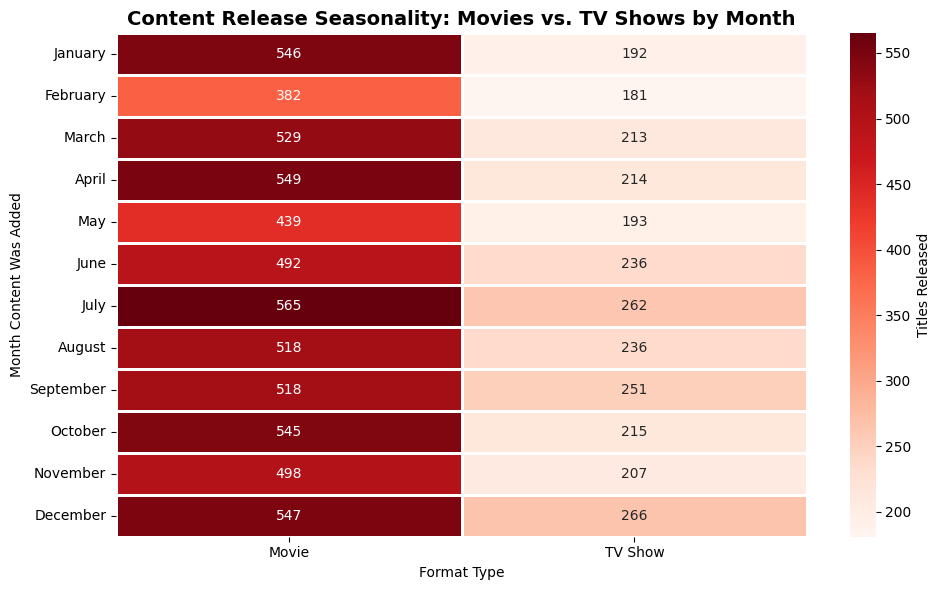

In [30]:
S
# 1. Create a categorical order for months so they sort chronologically, not alphabetically
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

# 2. Extract the month name from your clean date_added column
df['month_added'] = df['date_added'].dt.strftime('%B')

# 3. Create a pivot table cross-tabulating Month against Content Type
seasonality_matrix = pd.crosstab(df['month_added'], df['type']).reindex(month_order)

# 4. Plot the Seasonality Heatmap Matrix
plt.figure(figsize=(10, 6))
sns.heatmap(seasonality_matrix, annot=True, fmt='d', cmap='Reds', linewidths=1, cbar_kws={'label': 'Titles Released'})

plt.title('Content Release Seasonality: Movies vs. TV Shows by Month', fontsize=14, fontweight='bold')
plt.xlabel('Format Type')
plt.ylabel('Month Content Was Added')
plt.tight_layout()
plt.show()
